<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">08 · Word embeddings & topic modelling</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 3: turning words into vectors, and 6,000 abstracts into a map of what GLP-1 research is about</p>

| | |
|---|---|
| **Goal** | Learn meaning from co-occurrence (embeddings) and discover themes without labels (topic models) |
| **Corpus** | 6,160 PubMed abstracts (2022–2026) on tirzepatide, semaglutide, orforglipron and GLP-1 access |
| **Code** | `src/glp1_intel/nlp/topics.py` |
| **Outputs** | `data/03_processed/pubmed_topics.parquet` · `doctor_research_topics.parquet` (research themes for 736 linked doctors) |
| **Concepts** | distributional hypothesis · one-hot vs dense · Word2Vec (CBOW, skip-gram) · analogies · fastText & OOV · PCA · LDA · BERTopic (sentence embeddings → UMAP → HDBSCAN → c-TF-IDF) · topic diversity · topics over time |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import collections

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import FastText, Word2Vec
from sklearn.decomposition import LatentDirichletAllocation, PCA
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

from glp1_intel import viz
from glp1_intel.viz import MUTED, TEXT, TEXT_2, subtitle
from glp1_intel.notebook_style import show
from glp1_intel.nlp import topics as T

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]   # validated categorical palette
ab = T.abstracts()
print(f"{len(ab):,} abstracts")

6,160 abstracts


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 1 · From one-hot to dense vectors

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · The distributional hypothesis</b>

In notebook 07 every word was its own column (**one-hot / sparse**): `nausea` and `vomiting` were as unrelated as `nausea` and `Texas`.

**Distributional hypothesis** (Firth, 1957): *"You shall know a word by the company it keeps."* Words used in similar contexts have similar meanings.

**Word embeddings** turn this into maths: each word becomes a **dense vector** of ~100 numbers, learned so that words appearing in similar contexts end up **close together**. Similarity = cosine of the angle between vectors.

| | One-hot / TF-IDF | Embedding |
|---|---|---|
| Size | vocabulary (~30,000) | ~100 |
| Mostly zeros? | yes | no |
| `nausea` ↔ `vomiting` | unrelated | close |

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 2 · Word2Vec: CBOW vs skip-gram

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

**Word2Vec** (Mikolov et al., 2013) trains a tiny neural network on a fake task and keeps its weights as the embeddings:
- **CBOW** (continuous bag of words): predict the **centre word** from its context window, *[weight, ?, was, significant] → loss*. Fast, smooth for frequent words.
- **Skip-gram**: predict the **context words** from the centre word, *loss → [weight, was, significant]*. Slower, better for **rare** words (like new drug names).
- **Negative sampling** makes training cheap: instead of scoring all 13k words, the model learns to tell the true context word from a few random ones.

First we join frequent word pairs into **phrases** (`weight loss → weight_loss`) using a PMI-like score, as in notebook 06.

</div>

In [2]:
sentences = T.w2v_sentences(ab["text"])
phrased, phraser = T.add_phrases(sentences)
print(f"{len(sentences):,} sentences · {sum(map(len, sentences)):,} tokens")
learned = sorted({w for s in phrased for w in s if "_" in w})
words_only = [w for w in learned if all(part.isalpha() for part in w.split("_"))]
numeric = [w for w in learned if any(ch.isdigit() for ch in w)]
rng = np.random.default_rng(0)
print(f"{len(learned):,} phrases learned · {len(numeric):,} contain numbers (e.g. {numeric[:4]})")
print("Random sample of word phrases:", [str(w) for w in rng.choice(words_only, 20, replace=False)])

68,227 sentences · 1,594,418 tokens
1,983 phrases learned · 211 contain numbers (e.g. ['000_person-years', '0_00001', '0_0001', '0_001'])
Random sample of word phrases: ['trials_comparing', 'findings_underscore', 'erectile_dysfunction', 'vein_thrombosis', 'may_help', 'obstructive_sleep', 'more_than', 'were_calculated', 'oxidative_stress', 'per_day', 'confirmatory_secondary', 'shown_promise', 'pancreatic_cancer', 'adults_with_overweight', 'mild_to_moderate', 'baseline_characteristics', 'studies_published', 'matched_controls', 'reduced_ejection', 'among_individuals']


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- Real terms appear (`erectile_dysfunction`, `vein_thrombosis`, `obstructive_sleep`), but so does junk: grammar pairs (`may_help`, `more_than`, `were_calculated`) and **211 number phrases** (`0_0001`, `000_person-years`) glued together by statistics.
- Frequent word pairs aren't always meaningful units. Phrase detection is a heuristic, so check its output.

</div>

In [3]:
# workers=1 → fully reproducible (multi-threaded training changes results slightly run to run)
params = dict(vector_size=100, window=5, min_count=5, epochs=10, workers=1, seed=1)
skipgram = Word2Vec(phrased, sg=1, **params)
cbow     = Word2Vec(phrased, sg=0, **params)
print(f"Vocabulary with ≥ 5 occurrences: {len(skipgram.wv):,} words / phrases")

probe = ["nausea", "pancreatitis", "tirzepatide", "orforglipron", "weight_loss", "mounjaro"]
show(pd.DataFrame({
    "word": probe,
    "skip-gram nearest neighbours": [", ".join(w for w, _ in skipgram.wv.most_similar(p, topn=5)) for p in probe],
    "CBOW nearest neighbours":      [", ".join(w for w, _ in cbow.wv.most_similar(p, topn=5)) for p in probe],
}), "What each model learned: nearest words by cosine similarity")

Vocabulary with ≥ 5 occurrences: 13,633 words / phrases


word,skip-gram nearest neighbours,CBOW nearest neighbours
nausea,"diarrhea, vomiting, diarrhoea, constipation, nausea_vomiting","nausea_vomiting, diarrhea, constipation, vomiting, diarrhoea"
pancreatitis,"acute_pancreatitis, gallbladder, retinopathy, biliary, cholelithiasis","retinopathy, acute_pancreatitis, diabetic_ketoacidosis, aspiration, severe_hypoglycemia"
tirzepatide,"dulaglutide, once-weekly, efpeglenatide, cotadutide, semaglutide","dulaglutide, orforglipron, cagrisema, tzp, oral_semaglutide"
orforglipron,"danuglipron, mazdutide, ofg, elecoglipron, 14_mg","cagrisema, subcutaneous_semaglutide, once-weekly, cagrilintide, icosema"
weight_loss,"weight_reduction, wl, weight-loss, weight, weight_regain","weight_reduction, weight-loss, weight, body_weight, weight_management"
mounjaro,"zepbound, ozempic, wegovy, saxenda, marketed","zepbound, saxenda, wegovy, rybelsus, ozempic"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Without any medical dictionary, the vectors learned pharmacology from co-occurrence alone:
- **nausea** sits next to the other GI side effects (diarrhea, constipation, vomiting).
- **pancreatitis** neighbours gallbladder/biliary events, the related safety topic in GLP-1 labels.
- **orforglipron** sits with other **oral small-molecule GLP-1s** in development (danuglipron, lotiglipron…): the model inferred the drug class.
- **mounjaro** sits with other brand names (zepbound, ozempic, wegovy).

</div>

In [4]:
analogies = [("novo_nordisk", "semaglutide", "tirzepatide", "company of tirzepatide?"),
             ("mounjaro", "tirzepatide", "semaglutide", "brand of semaglutide?"),
             ("vomiting", "nausea", "diarrhea", "another GI side effect?")]
show(pd.DataFrame([{"question": q, "vector arithmetic": f"{a} − {b} + {c}",
                    "top answers": ", ".join(w for w, _ in skipgram.wv.most_similar(positive=[a, c], negative=[b], topn=4))}
                   for a, b, c, q in analogies]), "Word analogies: king − man + woman ≈ queen, GLP-1 edition")

question,vector arithmetic,top answers
company of tirzepatide?,novo_nordisk − semaglutide + tirzepatide,"company, eli_lilly, brand, name"
brand of semaglutide?,mounjaro − tirzepatide + semaglutide,"zepbound, wegovy, trade, glucagon-like-peptide"
another GI side effect?,vomiting − nausea + diarrhea,"constipation, abdominal_pain, decreased_appetite, dyspepsia"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Vector arithmetic captures **relationships**: *novo_nordisk − semaglutide + tirzepatide* lands near **eli_lilly** (company ↔ molecule), and the brand analogy lands among GLP-1 brand names.
With only ~1.6 million words some answers are noisy. Embeddings trained on billions of words are much sharper, but the principle is visible.

</div>

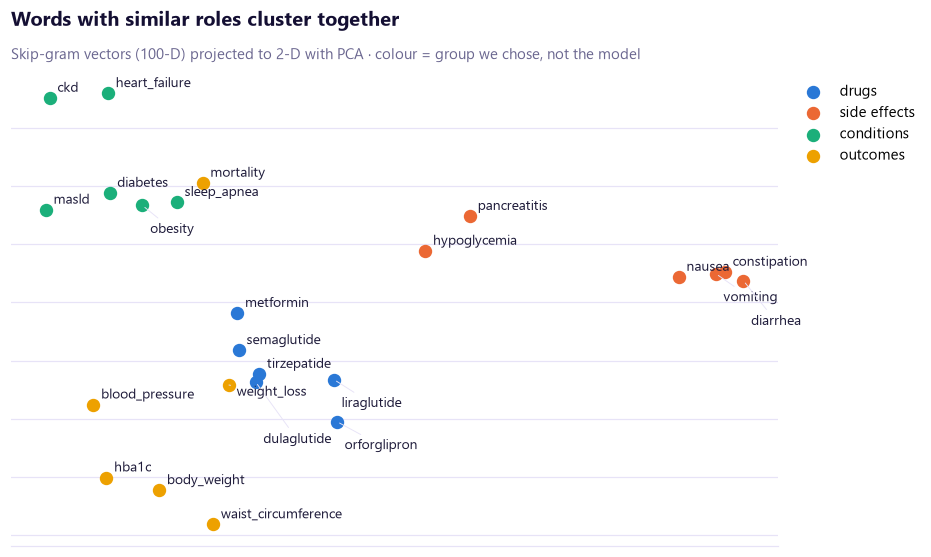

In [5]:
groups = {
    "drugs":        ["tirzepatide", "semaglutide", "dulaglutide", "liraglutide", "orforglipron", "metformin"],
    "side effects": ["nausea", "vomiting", "diarrhea", "constipation", "pancreatitis", "hypoglycemia"],
    "conditions":   ["obesity", "diabetes", "heart_failure", "ckd", "masld", "sleep_apnea"],
    "outcomes":     ["weight_loss", "hba1c", "mortality", "blood_pressure", "body_weight", "waist_circumference"],
}
words = [(w, g) for g, ws in groups.items() for w in ws if w in skipgram.wv]
xy = PCA(2, random_state=0).fit_transform(np.array([skipgram.wv[w] for w, _ in words]))

fig, ax = plt.subplots(figsize=(9, 5.6))
for (g, color) in zip(groups, CAT):
    idx = [i for i, (_, gg) in enumerate(words) if gg == g]
    ax.scatter(xy[idx, 0], xy[idx, 1], s=60, color=color, label=g, zorder=3)
viz.label_points(ax, xy[:, 0], xy[:, 1], [w for w, _ in words])            # labels nudged apart, never overlapping
ax.grid(axis="both"); ax.set_xticklabels([]); ax.set_yticklabels([])
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Words with similar roles cluster together")
subtitle(ax, "Skip-gram vectors (100-D) projected to 2-D with PCA · colour = group we chose, not the model")
viz.save(fig, "08_1_embedding_map")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The model was never told these groups, yet **side effects**, **drugs**, **conditions** and **outcomes** form separate regions. Note where `weight_loss` lands: **among the drugs**, because in GLP-1 papers it's mentioned in the same breath as the molecules. PCA squeezes 100 dimensions into 2, so some overlap is expected; distances in the full space are more faithful.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitation · No context</b>

**One vector per word, whatever the context.** "*discharge*" (from hospital) and "*discharge*" (a symptom) share one vector; so do "*cold*" (temperature) and "*cold*" (illness). Word2Vec can't handle **polysemy**.
**Contextual** models (BERT, notebook 10) give a different vector to each occurrence of a word depending on its sentence. That's the step from Level 3 to Level 4.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 3 · fastText: handling words never seen in training

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

Word2Vec has no vector for an **out-of-vocabulary (OOV)** word: a typo or a new drug name. **fastText** represents a word as the sum of its **character n-grams** (`<ti`, `tir`, `irz`, … `de>`), so it can build a vector for *any* string from its pieces. That's handy for messy rep notes ("tirzepatid", "nauseous").

</div>

In [6]:
fasttext = FastText(phrased, sg=1, **params)
oov = ["tirzepatid", "semaglutid", "nauseous", "orforglipronn"]
show(pd.DataFrame([{"word (misspelt / unseen)": w, "in Word2Vec vocab?": w in skipgram.wv,
                    "fastText nearest": ", ".join(x for x, _ in fasttext.wv.most_similar(w, topn=4))} for w in oov]),
     "fastText builds vectors for unseen words from character n-grams")

word (misspelt / unseen),in Word2Vec vocab?,fastText nearest
tirzepatid,False,"tirzepatide, tirze, tirzepatide-specific, tirzepatide-treated"
semaglutid,False,"semaglutide-, semaglutide, semaglutide-sglt2i, sema-sc"
nauseous,False,"nausea_vomiting, nausea_and_vomiting, nausea, dyspepsia"
orforglipronn,False,"orforglipron, aleniglipron, lotiglipron, danuglipron"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Word2Vec has **no vector** for any of these, while fastText maps each to the right word (`tirzepatid → tirzepatide`, `orforglipronn → orforglipron`). The same subword idea powers the BPE/WordPiece tokenizers from notebook 06.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 4 · Topic modelling I: LDA

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

**Topic modelling** discovers themes in a corpus **without labels** (unsupervised).

**LDA** (latent Dirichlet allocation) assumes each document is a **mixture of topics**, and each topic is a **distribution over words**. Training finds the topics and mixtures that best explain the word counts.
- Input: a bag-of-words matrix (word order ignored)
- You choose the number of topics *k*
- Output: top words per topic + a topic mixture per document

</div>

In [7]:
vec = CountVectorizer(stop_words="english", min_df=10, max_df=0.5, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]{2,}\b")
dtm = vec.fit_transform(ab["text"])
lda = LatentDirichletAllocation(n_components=12, learning_method="batch", max_iter=20, random_state=0).fit(dtm)

vocab = vec.get_feature_names_out()
lda_topics = [[vocab[i] for i in comp.argsort()[::-1][:8]] for comp in lda.components_]
show(pd.DataFrame({"LDA topic": range(12), "top words": [" · ".join(t) for t in lda_topics]}), "LDA with k = 12")

LDA topic,top words
0,health · care · use · study · medication · prescribing · using · medications
1,mass · body · loss · mice · muscle · levels · fat · study
2,tirzepatide · participants · body · baseline · placebo · reduction · mean · study
3,clinical · evidence · disease · cardiovascular · risk · review · therapies · management
4,metabolic · liver · effects · disease · fibrosis · masld · mash · inflammation
5,tirzepatide · gip · dual · agonists · oral · agonist · insulinotropic · glucose-dependent
6,case · patient · therapy · tirzepatide · loss · symptoms · use · report
7,study · associated · months · years · cohort · use · risk · compared
8,loss · health · management · surgery · lifestyle · medications · bariatric · interventions
9,cardiovascular · risk · heart · failure · disease · events · kidney · outcomes


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Several LDA topics are recognisable (liver/MASH, cardiovascular, tirzepatide trial results, GIP/dual agonists, a preclinical *mice/muscle* topic, lifestyle and bariatric surgery), but others are dominated by **generic research words** (`study`, `health`, `use`, `risk`, `cohort`).
LDA only sees word counts, so two abstracts about the same idea in different words don't group together, and **k must be guessed**.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 5 · Topic modelling II: BERTopic

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · BERTopic in four steps</b>

**BERTopic** (Grootendorst, 2022) clusters **meanings** instead of word counts, in four steps:

| Step | Tool | What it does |
|---|---|---|
| 1 · Embed | `all-MiniLM-L6-v2` sentence transformer | each abstract → a 384-number vector of its *meaning* |
| 2 · Reduce | **UMAP** | 384 → 5 dimensions, keeping neighbours close (clustering in high dimensions fails: the *curse of dimensionality*) |
| 3 · Cluster | **HDBSCAN** | finds dense groups; **chooses the number of topics itself**; leaves unclear docs as **outliers (−1)** |
| 4 · Describe | **c-TF-IDF** | TF-IDF where each *cluster* is one big document, giving words that distinguish this topic from the others |

</div>

In [8]:
emb = T.embed(ab["doc"].tolist())               # cached; first run ~5 min on CPU
model, topic_ids = T.fit_bertopic(ab["doc"].tolist(), emb)
ab["topic"] = topic_ids
ab["topic_label"] = [T.topic_label(model, t) for t in topic_ids]
ab["pmid"] = ab["doc_id"].str.replace("pmid:", "", regex=False)

info = (ab.groupby(["topic", "topic_label"]).size().rename("abstracts").reset_index()
          .sort_values("abstracts", ascending=False))
print(f"Topics found: {ab['topic'].max() + 1} · outliers: {(ab['topic'] == -1).mean():.0%}")
show(info.head(30), "BERTopic topics (largest first)")

Topics found: 28 · outliers: 25%


topic,topic_label,abstracts
-1,outliers (no clear topic),"1,549"
0,tirzepatide · weight · mg · diabetes,743
1,kidney · inhibitors · patients · ckd,577
2,receptor · glp1 · obesity · peptide,513
3,liver · mash · masld · fibrosis,240
4,semaglutide · weight · obesity · 24,208
5,oral · oral semaglutide · semaglutide · hba1c,174
6,glp1 · weight · obesity · loss,166
7,bone · glp1 · patients · fusion,152
8,surgery · bariatric · bariatric surgery · weight,150


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

BERTopic finds **~28 coherent themes** on its own, and many map straight to commercial and medical questions:
- **Safety signals:** optic neuropathy (NAION), psychiatric/suicidal ideation, cancer/thyroid, pancreatitis case reports, perioperative **aspiration**, plus pharmacovigilance reporting studies
- **New indications:** MASH/liver, heart failure (HFpEF), chronic kidney disease, sleep apnoea, PCOS/reproductive, psoriasis, alcohol use disorder, dementia
- **Market access:** cost-effectiveness, adolescents, bariatric surgery comparisons
- **Pipeline:** a separate **orforglipron** cluster

About a quarter of abstracts are **outliers** (−1): HDBSCAN prefers "unsure" over forcing a bad fit, a feature, not a bug.

</div>

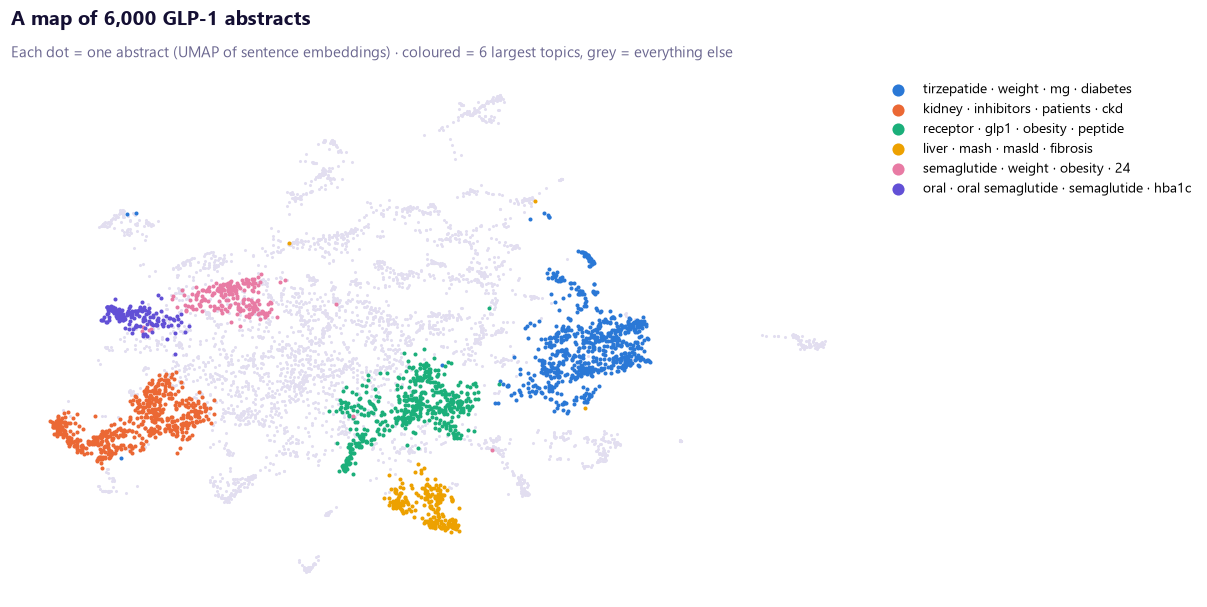

In [9]:
xy = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=42).fit_transform(emb)
top6 = info[info["topic"] != -1].head(6)

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.scatter(xy[:, 0], xy[:, 1], s=4, color="#E2DEF0", linewidths=0, zorder=1)          # all other abstracts
for (tid, label), color in zip(top6[["topic", "topic_label"]].values, CAT):
    m = ab["topic"].values == tid
    ax.scatter(xy[m, 0], xy[m, 1], s=7, color=color, linewidths=0, label=label, zorder=2)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for side in ("bottom", "left"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), markerscale=3, fontsize=9)
ax.set_title("A map of 6,000 GLP-1 abstracts")
subtitle(ax, "Each dot = one abstract (UMAP of sentence embeddings) · coloured = 6 largest topics, grey = everything else")
viz.save(fig, "08_2_topic_map")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Abstracts about the same subject sit together **because their meaning is similar**, not because they share exact words. The six largest topics occupy distinct regions; grey dots are smaller topics and outliers.

</div>

In [10]:
def diversity(topic_word_lists, n=10):
    """Share of unique words among the top-n words of all topics (1.0 = no overlap)."""
    words = [w for t in topic_word_lists for w in t[:n]]
    return len(set(words)) / len(words)

bt_words = [[w for w, _ in model.get_topic(t)[:10]] for t in sorted(set(topic_ids)) if t != -1]
lda_words = [[vocab[i] for i in comp.argsort()[::-1][:10]] for comp in lda.components_]
show(pd.DataFrame([
    {"method": "LDA (k = 12, chosen by us)", "topics": 12, "topic diversity": diversity(lda_words), "uses word order / meaning": "no"},
    {"method": "BERTopic (k found by HDBSCAN)", "topics": len(bt_words), "topic diversity": diversity(bt_words), "uses word order / meaning": "yes (embeddings)"},
]), "LDA vs BERTopic", precision=2)

method,topics,topic diversity,uses word order / meaning
"LDA (k = 12, chosen by us)",12,0.72,no
BERTopic (k found by HDBSCAN),28,0.75,yes (embeddings)


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Topic diversity** (share of unique words among each topic's top 10) is **similar**: ~0.72 vs ~0.75. On this single number the methods look alike.
- The real difference shows when you **read** them: BERTopic separates fine-grained themes (NAION, alcohol use disorder, perioperative aspiration, psoriasis) that LDA's 12 topics blend into broad buckets, and it chose the number of topics itself.
- Lesson: one metric rarely settles a comparison. Topic quality is judged with several metrics (**coherence**, diversity, stability across seeds) and, above all, by **domain experts reading the topics**.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 6 · What's emerging? Topics over time

</div>

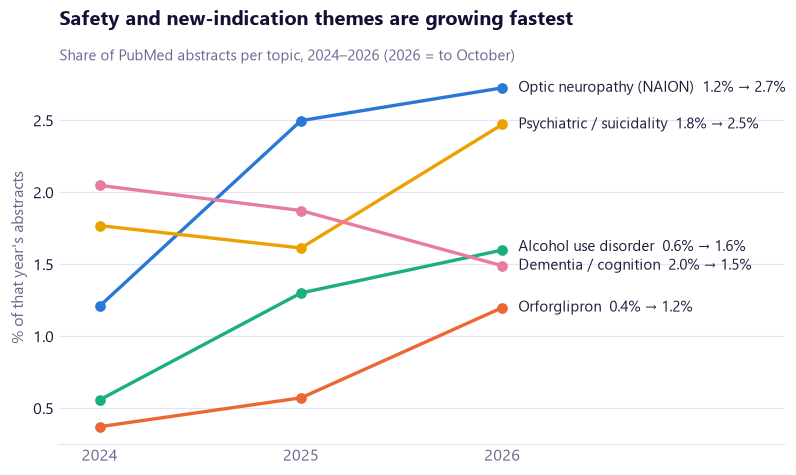

In [11]:
recent = ab[pd.to_numeric(ab["year"], errors="coerce").between(2024, 2026)].copy()
recent["year"] = recent["year"].astype(int)
share = pd.crosstab(recent["topic_label"], recent["year"], normalize="columns") * 100

themes = {"optic": "Optic neuropathy (NAION)", "orforglipron": "Orforglipron", "alcohol": "Alcohol use disorder",
          "psychiatric": "Psychiatric / suicidality", "dementia": "Dementia / cognition"}
fig, ax = plt.subplots(figsize=(8.5, 4.4))
items = []
for (key, name), color in zip(themes.items(), CAT):
    row = share[share.index.str.contains(key)].iloc[0]
    ax.plot(row.index, row.values, color=color, marker="o", lw=2.2)
    items.append((f"{name}  {row.iloc[0]:.1f}% → {row.iloc[-1]:.1f}%", row.values[-1]))
ax.set_xticks([2024, 2025, 2026]); ax.set_xlim(2023.8, 2027.4)
viz.end_labels(ax, 2026.08, items, min_gap=0.13)
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
ax.set_ylabel("% of that year's abstracts")
ax.set_title("Safety and new-indication themes are growing fastest")
subtitle(ax, "Share of PubMed abstracts per topic, 2024–2026 (2026 = to October)")
viz.save(fig, "08_3_emerging_topics")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Optic neuropathy (NAION)** more than doubles its share (≈1.2% → 2.7%): a safety question reps will increasingly hear.
- **Orforglipron** triples as phase-3 results and approval arrive, and **alcohol use disorder** grows as a possible new indication.
- **Dementia** research holds steady or shrinks in share while other themes expand.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out</b>

Our corpus was built from **queries with different date ranges** (semaglutide 2024+, tirzepatide 2022+), so we compare **2024–2026 only**, when all queries are active, and use **shares**, not counts.
Topic share measures **research attention**, not clinical importance or real-world frequency.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 7 · Each doctor's research interests

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

Notebook 05 linked PubMed authors to doctors by name. Joining those links with each abstract's topic gives a **research-interest profile** per doctor: exactly the *"what does Dr X care about?"* line in the pre-visit brief.

</div>

In [12]:
ab[["doc_id", "pmid", "year", "query", "title", "topic", "topic_label"]].to_parquet(T.TOPICS_FILE, index=False)
doc_themes = T.doctor_topics(ab)
print(f"Doctors with a research-theme profile: {len(doc_themes):,}")
show(doc_themes.sort_values("n_topic_papers", ascending=False).head(8)
               .assign(npi=lambda d: d["npi"].str[:3] + "•••••••"), "Research themes of the most-published linked doctors (NPI masked)")

Doctors with a research-theme profile: 736


npi,n_topic_papers,research_themes
158•••••••,20,hfpef · heart · heart failure · failure | kidney · inhibitors · patients · ckd | tirzepatide · weight · mg · diabetes
151•••••••,19,hfpef · heart · heart failure · failure | tirzepatide · weight · mg · diabetes
174•••••••,16,kidney · inhibitors · patients · ckd | tirzepatide · weight · mg · diabetes | receptor · glp1 · obesity · peptide
106•••••••,15,tirzepatide · weight · mg · diabetes | tirzepatide · semaglutide · mg · weight | orforglipron · mg · placebo · oral
144•••••••,15,kidney · inhibitors · patients · ckd | semaglutide · weight · obesity · 24 | tirzepatide · weight · mg · diabetes
143•••••••,11,tirzepatide · weight · mg · diabetes | glp1 · weight · obesity · loss | orforglipron · mg · placebo · oral
131•••••••,9,tirzepatide · weight · mg · diabetes | obesity · medications · weight · antiobesity | tirzepatide · semaglutide · mg · weight
173•••••••,9,kidney · inhibitors · patients · ckd | optic · neuropathy · risk · optic neuropathy | reporting · adverse · ror · reports


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Doctors now carry themes such as *heart failure*, *kidney*, *tirzepatide trials* or *orforglipron*. A rep meeting a cardiologist who publishes on HFpEF can lead with **heart-failure evidence**, not generic weight-loss messaging: relevance, the core of good targeting.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out</b>

Profiles exist only for doctors whose PubMed name matched **uniquely** (notebook 05), which favours academic prescribers. Most community doctors don't publish; their interests will come from **visit notes** (notebooks 09–12).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 8 · Summary

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. Embeddings trained on 1.6M words are **noisy**; large pre-trained models are far stronger (we'll use them from notebook 10).
2. Word2Vec/fastText give **one vector per word**, so no context and no polysemy.
3. Topic models are **unsupervised**: labels come from top words and need human judgement; results shift with parameters (`min_cluster_size`, `k`).
4. Topic shares reflect **publication attention** and our query design, not clinical truth.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** domain word embeddings, an OOV-robust fastText model, LDA vs BERTopic, a research-trend view, and research-theme profiles for 736 doctors.
**Next:** notebook 09, generating a **synthetic, labelled visit-notes dataset** with an LLM, the data our classifiers and the rep view will run on.

**Check your understanding**
- *What is the distributional hypothesis?* Words in similar contexts have similar meanings; embeddings turn that into geometry.
- *CBOW vs skip-gram?* Predict the word from its context vs the context from the word; skip-gram is better for rare words.
- *Why fastText?* Character n-grams give vectors for unseen or misspelt words.
- *Main weakness of Word2Vec?* One vector per word, so no context; solved by contextual models like BERT.
- *How does BERTopic work?* Sentence embeddings → UMAP → HDBSCAN → c-TF-IDF; it finds k itself and allows outliers.
- *LDA vs BERTopic?* LDA = word-count mixtures with a fixed k; BERTopic = meaning clusters, finer themes, k chosen by HDBSCAN (diversity alone barely differed).
- *How would you evaluate topics?* Coherence, diversity, stability across seeds, and expert review.

</div>